In [3]:
import os
import glob
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
import matplotlib.patheffects as PathEffects
import arviz as az
from Functions_PyMC_MHWdetection import *

az.style.use("arviz-darkgrid")

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.constrained_layout.use": True,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
    }
)



def get_hemisphere(lat: float) -> str:
    """
    Return hemisphere based on latitude.
    
    Parameters
    ----------
    lat : float
        Latitude in degrees.
    
    Returns
    -------
    str
        "Northern Hemisphere" or "Southern Hemisphere"
    """
    if lat >= 0:
        return "Northern Hemisphere"
    else:
        return "Southern Hemisphere"



In [4]:
# --- Step 1: find all netCDF files in the current folder
current_folder = os.getcwd()
nc_files = glob.glob(f"{current_folder}\data\*.nc")   # or "*.nc4" depending on your files
labels = ['Japan','North West Shelf', 'South Western Australia',  'UK']

nc_files

['C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\Japan.nc',
 'C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\NorthWestShelf.nc',
 'C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\SouthWA.nc',
 'C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\UK.nc']

In [5]:


locations = []
timeseries = []

for f in nc_files:
    ds = xr.open_dataset(f)
    ds = ds.sel(time = slice(pd.to_datetime('1994-01-01'),pd.to_datetime('2025-01-01')))
    # Get lat/lon
    if "lat" in ds:
        lat_values = ds["lat"].values
    else:
        lat_values = ds["latitude"].values

    if "lon" in ds:
        lon_values = ds["lon"].values
    else:
        lon_values = ds["longitude"].values
    print(f'\n{f}')
    print(f'Lat: {lat_values[0],lat_values[-1]}')
    print(f'Lon: {lon_values[0],lon_values[-1]}')
    
    lat = float(lat_values.mean())
    lon = float(lon_values.mean())

    print(get_hemisphere(lat))
    # Store location
    locations.append((lon, lat, f))

    # Try to extract SST or temperature variable
    if "sst" in ds:
        ts = ds["sst"].mean(dim=[d for d in ds["sst"].dims if d != "time"]).values
        time = ds["time"].values
    elif "temperature" in ds:
        ts = ds["temperature"].mean(dim=[d for d in ds["temperature"].dims if d != "time"]).values
        time = ds["time"].values
    elif "analysed_sst" in ds:
        ts = ds["analysed_sst"].mean(dim=[d for d in ds["analysed_sst"].dims if d != "time"]).values
        time = ds["time"].values
    else:
        raise ValueError(f"No SST/temperature variable found in {f}")

    timeseries.append((time, ts))
    ds.close()


C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\Japan.nc
Lat: (np.float32(31.02501), np.float32(31.97501))
Lon: (np.float32(126.025), np.float32(126.975006))
Northern Hemisphere

C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\NorthWestShelf.nc
Lat: (np.float32(-18.974993), np.float32(-18.024994))
Lon: (np.float32(118.025), np.float32(118.975006))
Southern Hemisphere

C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\SouthWA.nc
Lat: (np.float32(-32.024994), np.float32(-31.874994))
Lon: (np.float32(115.325005), np.float32(115.475006))
Southern Hemisphere

C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\UK.nc
Lat: (np.float32(52.025013), np.float32(52.97501))
Lon: (np.float32(-11.975), np.float32(-11.025001))
Northern Hemisphere


126.50001525878906 31.500009536743164 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\Japan.nc
118.50001525878906 -18.49999237060547 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\NorthWestShelf.nc
115.4000015258789 -31.949995040893555 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\SouthWA.nc
-11.5 52.50000762939453 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\UK.nc


C:\Users\24048369\AppData\Local\Temp\ipykernel_24480\1854500381.py:79: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


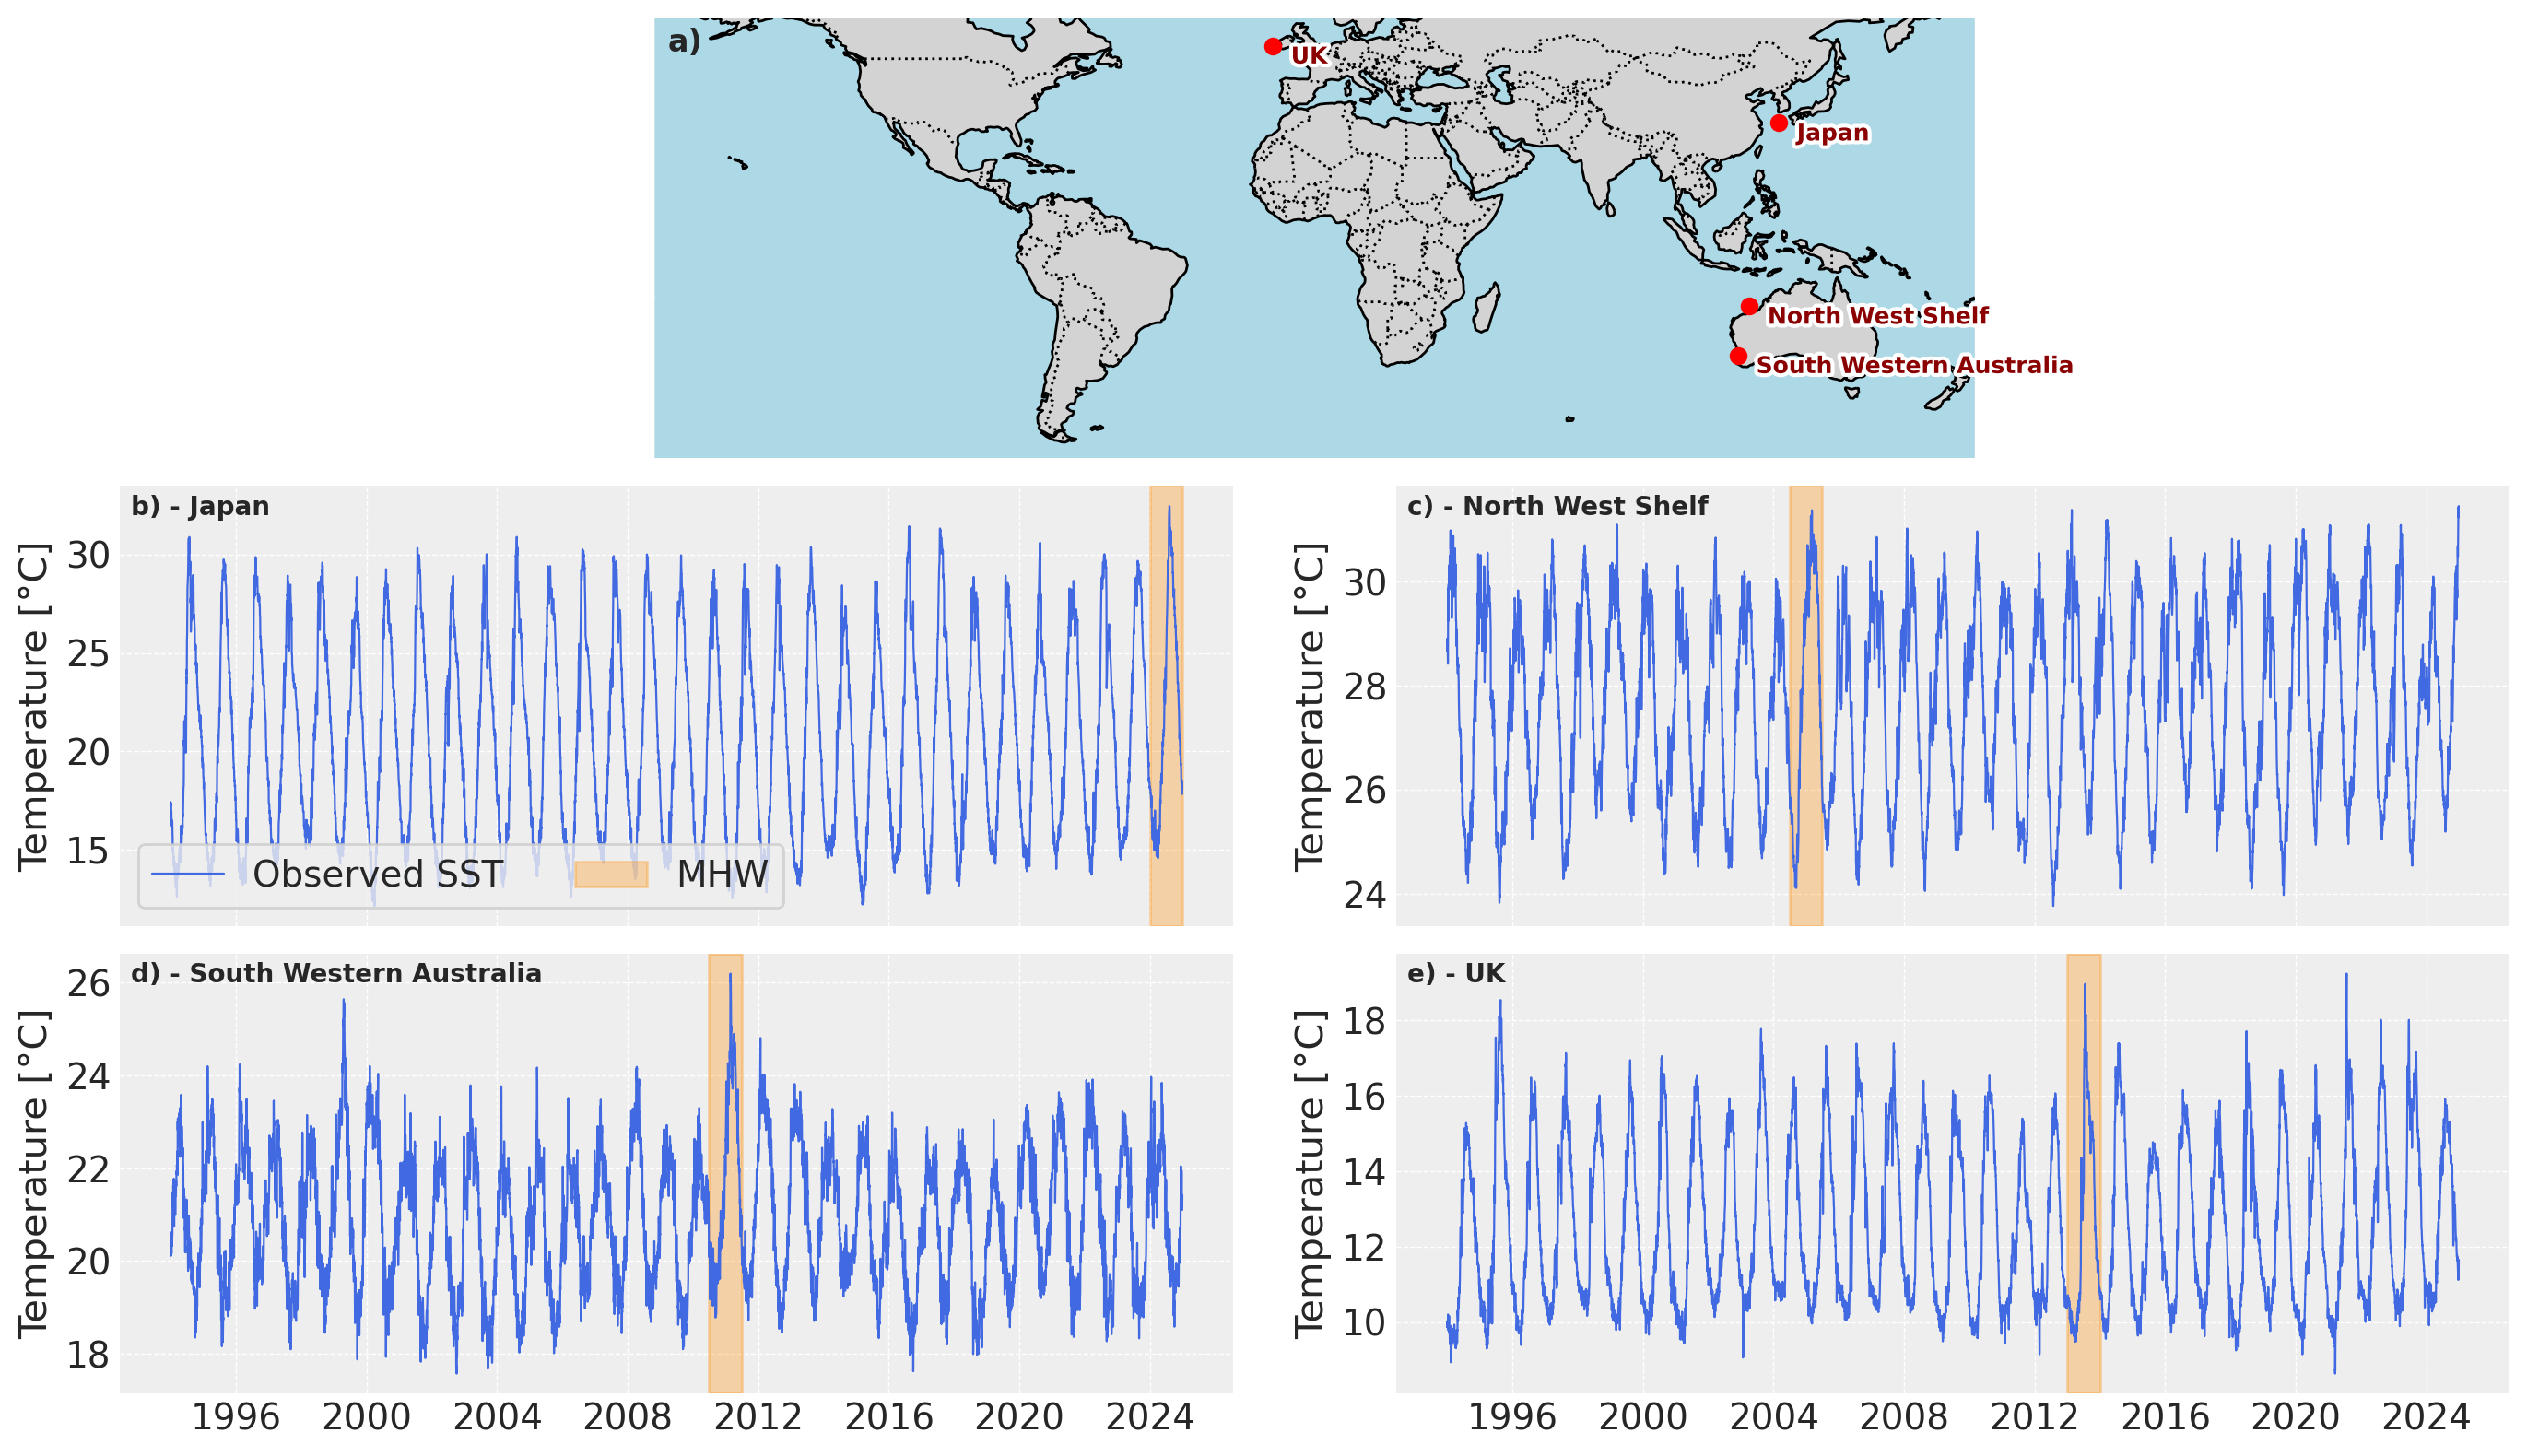

In [6]:



# --- Create figure with 2 rows: top (map), bottom (2x2 timeseries) ---
fig = plt.figure(figsize=(14, 8), dpi=200)

# Top: world map (a)
ax_map = plt.subplot2grid((3, 2), (0, 0), colspan=2, projection=ccrs.PlateCarree())
ax_map.set_global()
ax_map.coastlines()
ax_map.add_feature(cfeature.BORDERS, linestyle=":")
ax_map.add_feature(cfeature.LAND, facecolor="lightgray")
ax_map.add_feature(cfeature.OCEAN, facecolor="lightblue")

# Bottom: 2x2 timeseries (b, c, d, e)
axes_ts = [
    plt.subplot2grid((3, 2), (1, 0)),  # b
    plt.subplot2grid((3, 2), (1, 1)),  # c
    plt.subplot2grid((3, 2), (2, 0)),  # d
    plt.subplot2grid((3, 2), (2, 1))   # e
]

panel_labels = ['a)', 'b)', 'c)', 'd)', 'e)']

# --- Plot data ---
# Map
for ii, ((lon, lat, fname), (time, ts)) in enumerate(zip(locations, timeseries)):
    print(lon, lat, fname)
    ax_map.plot(lon, lat, "ro", markersize=6, transform=ccrs.PlateCarree())
    txt = ax_map.text(lon + 5, lat, labels[ii], transform=ccrs.PlateCarree(),
                fontsize=9, va='top', weight='bold', color='darkred')
    txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

# Add panel label to map
ax_map.text(0.01, 0.98, panel_labels[0], transform=ax_map.transAxes,
            ha='left', va='top', fontsize=12, weight='bold')

ax_map.set_ylim(-60,60)


# Timeseries
for ii, ((lon, lat, fname), (time, ts)) in enumerate(zip(locations, timeseries)):
    ax = axes_ts[ii]
    ax.plot(time, ts - 273.15, color="royalblue", linewidth=0.8,label='Observed SST')
    
    if ii < 2:  # hide x labels on top row of bottom grid
        ax.set_xticklabels([])
    # Panel label
    ax.text(0.01, 0.98, f"{panel_labels[ii+1]} - {labels[ii]}", transform=ax.transAxes,
            ha='left', va='top', fontsize=10, weight='bold')

# --- Highlight MHW events ---


ax = axes_ts[0]
ds_start,ds_end = pd.to_datetime('2024-01-01'),pd.to_datetime('2025-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3, label = 'MHW')
ax.set_ylabel("Temperature [°C]")
ax.legend(loc = 'lower left', ncols = 2, frameon=True)

ax = axes_ts[1]
ds_start,ds_end = pd.to_datetime('2004-07-01'),pd.to_datetime('2005-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")


ax = axes_ts[2]
ds_start,ds_end = pd.to_datetime('2010-07-01'),pd.to_datetime('2011-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")


ax = axes_ts[3]
ds_start,ds_end = pd.to_datetime('2013-01-01'),pd.to_datetime('2014-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")




# Adjust layout
plt.tight_layout()

# plt.savefig(os.path.join(os.getcwd(), "Map_timeseries.png"), dpi=300)
# plt.savefig(os.path.join(os.getcwd(), "Map_timeseries.pdf"), dpi=300)


plt.show()


126.50001525878906 31.500009536743164 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\Japan.nc
118.50001525878906 -18.49999237060547 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\NorthWestShelf.nc
115.4000015258789 -31.949995040893555 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\SouthWA.nc
-11.5 52.50000762939453 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\UK.nc


C:\Users\24048369\AppData\Local\Temp\ipykernel_24480\350633882.py:133: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\24048369\AppData\Local\Temp\ipykernel_24480\350633882.py:133: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


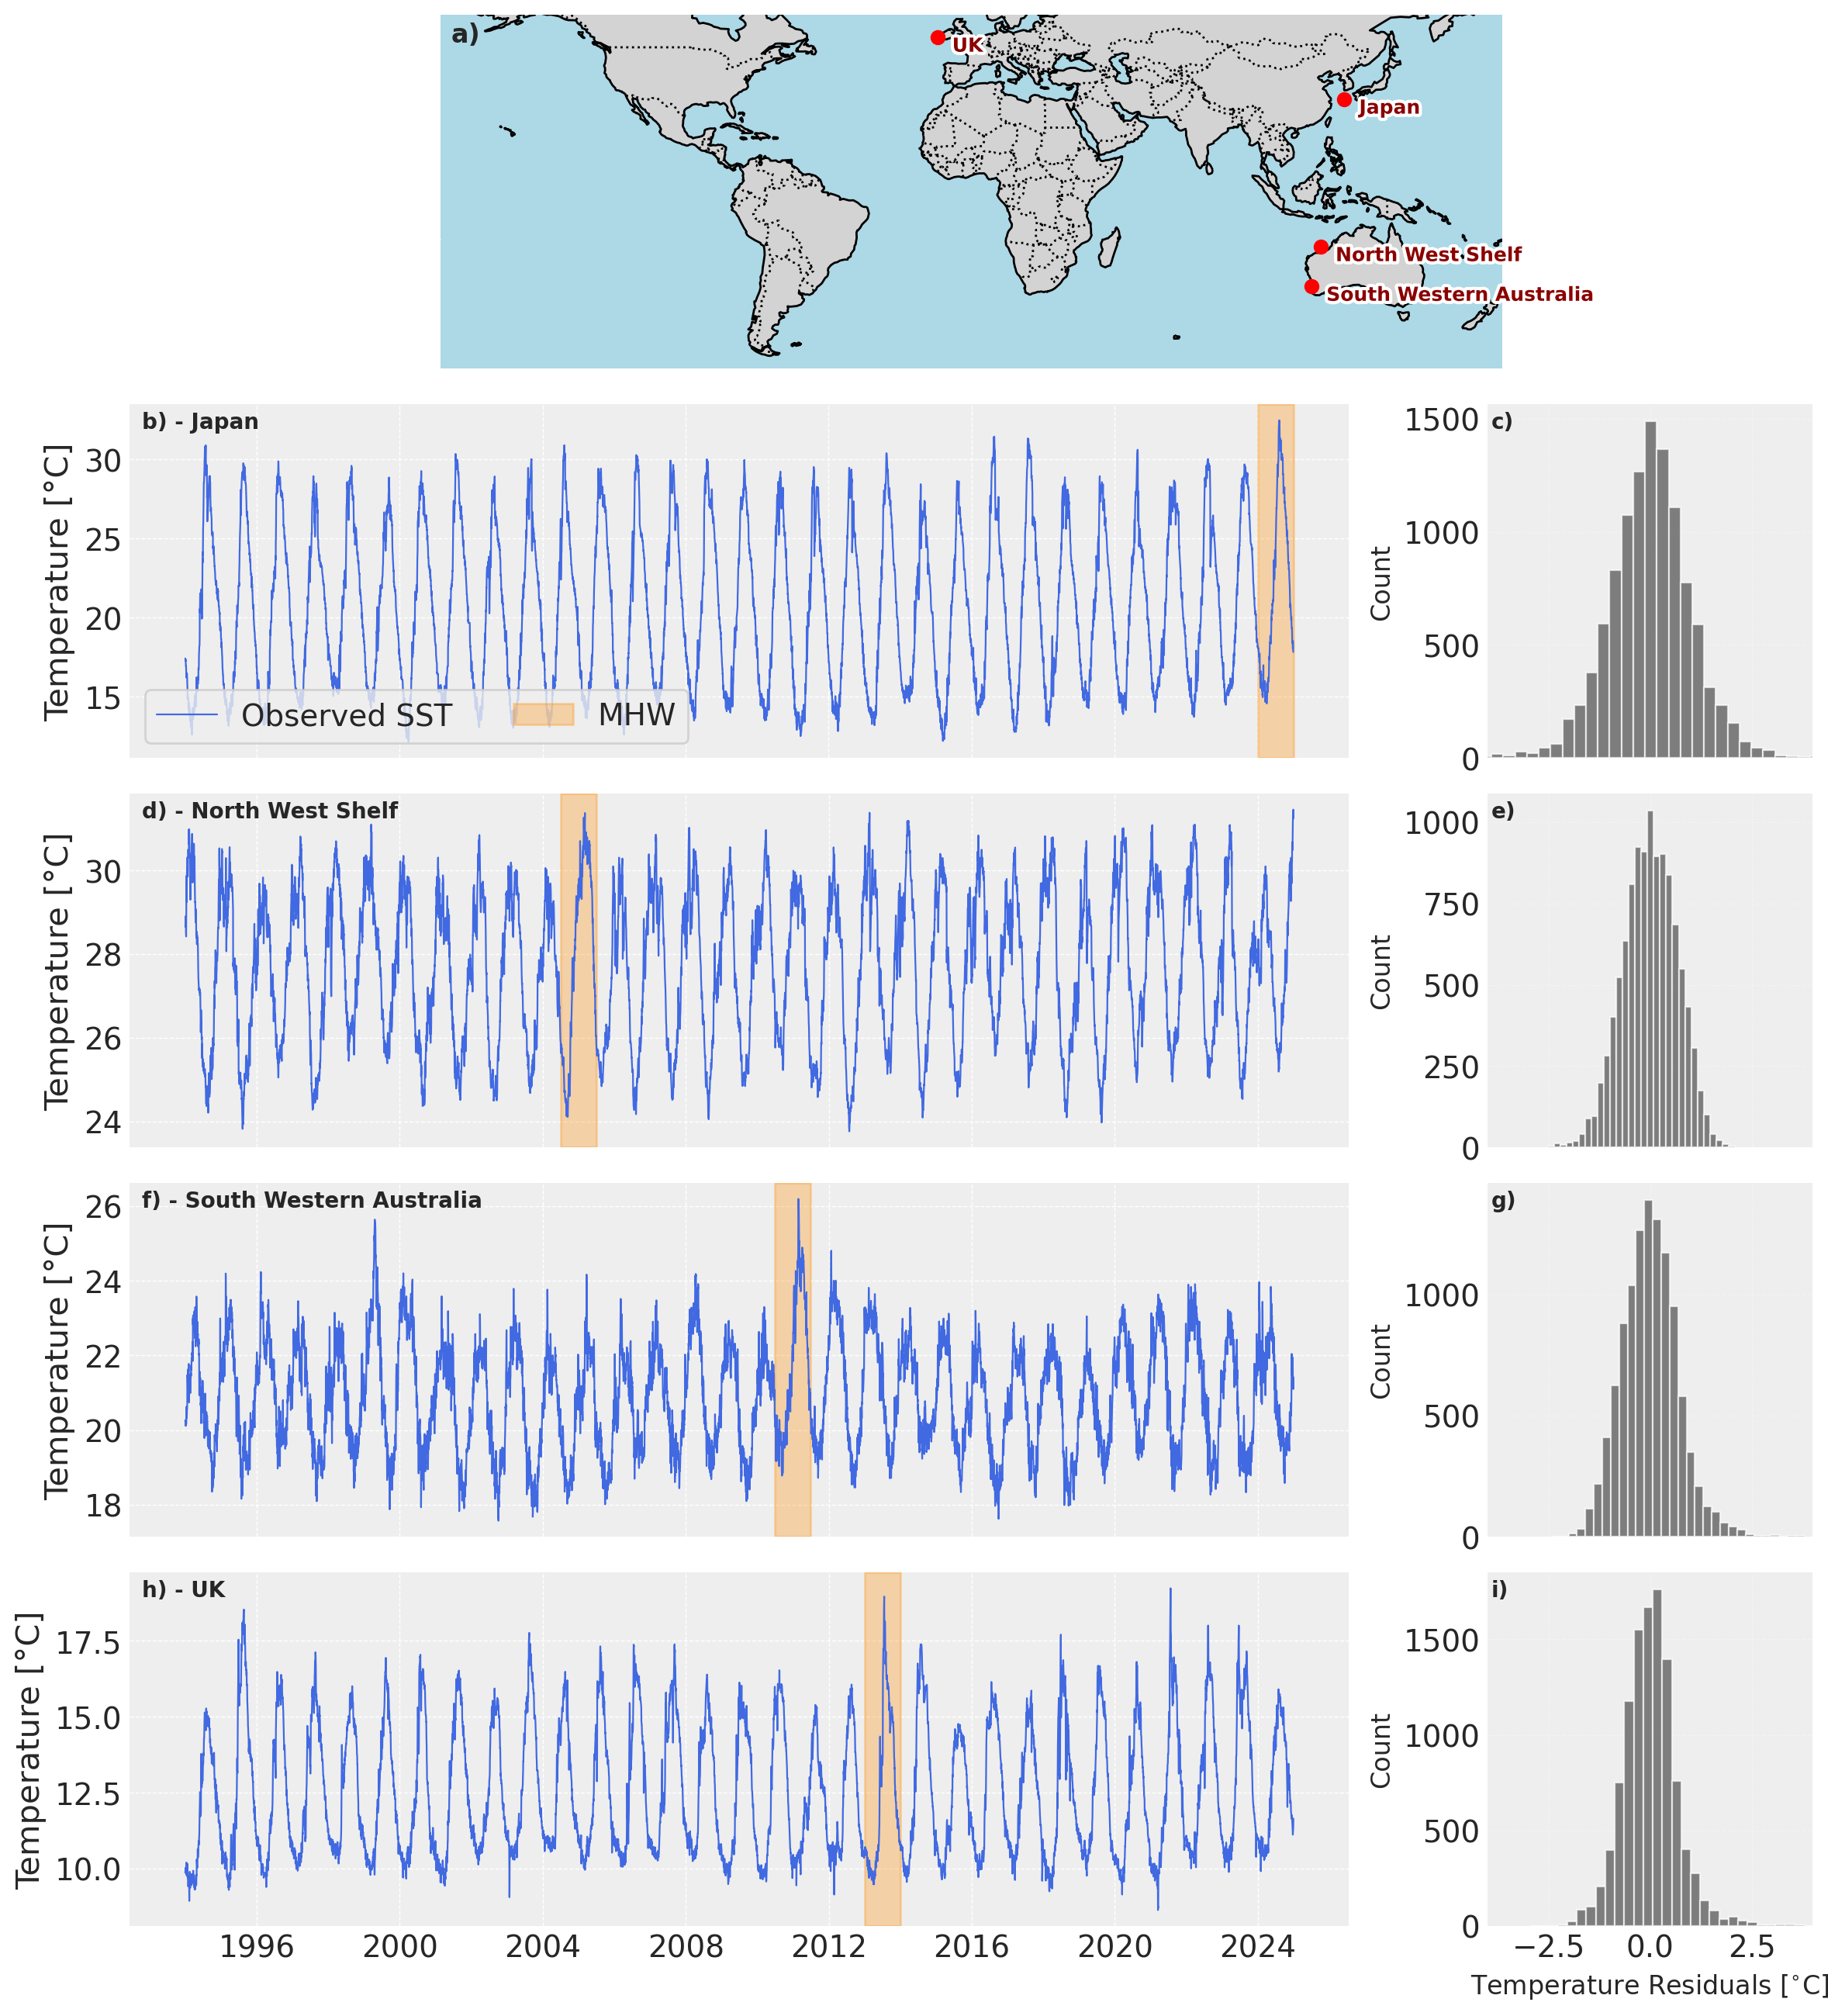

In [7]:



# --- Create figure with 2 rows: top (map), bottom (2x2 timeseries) ---
# fig = plt.figure(figsize=(14, 8), dpi=200)

import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 16), dpi=200)

gs = gridspec.GridSpec(
    nrows=5,
    ncols=2,
    figure=fig,
    width_ratios=[3, 0.8],     # ⬅ timeseries wider than histograms
    height_ratios=[1, 1, 1, 1, 1],  # ⬅ taller map
    hspace=0.1,
    wspace=0.18
)

# --- Map (top, centered across both columns) ---
ax_map = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())
ax_map.set_global()
ax_map.coastlines()
ax_map.add_feature(cfeature.BORDERS, linestyle=":")
ax_map.add_feature(cfeature.LAND, facecolor="lightgray")
ax_map.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax_map.set_ylim(-60, 60)

# --- Left column: timeseries ---
axes_ts = [fig.add_subplot(gs[i, 0]) for i in range(1, 5)]

# --- Right column: histograms ---
axes_his = [fig.add_subplot(gs[i, 1]) for i in range(1, 5)]

panel_labels = ['a)', 'b)', 'd)', 'f)', 'h)']
panel_labels2 = ['c)', 'e)', 'g)', 'i)']
# --- Plot data ---
# Map
for ii, ((lon, lat, fname), (time, ts)) in enumerate(zip(locations, timeseries)):
    print(lon, lat, fname)
    ax_map.plot(lon, lat, "ro", markersize=6, transform=ccrs.PlateCarree())
    txt = ax_map.text(lon + 5, lat, labels[ii], transform=ccrs.PlateCarree(),
                fontsize=9, va='top', weight='bold', color='darkred')
    txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

# Add panel label to map
ax_map.text(0.01, 0.98, panel_labels[0], transform=ax_map.transAxes,
            ha='left', va='top', fontsize=12, weight='bold')

ax_map.set_ylim(-60,60)


# Timeseries
for ii, ((lon, lat, fname), (time, ts)) in enumerate(zip(locations, timeseries)):
    ax = axes_ts[ii]
    ax.plot(time, ts - 273.15, color="royalblue", linewidth=0.8,label='Observed SST')
    
    if ii < 3:  # hide x labels on top row of bottom grid
        ax.set_xticklabels([])
    # Panel label
    ax.text(0.01, 0.98, f"{panel_labels[ii+1]} - {labels[ii]}", transform=ax.transAxes,
            ha='left', va='top', fontsize=10, weight='bold')



    hemis = get_hemisphere(lat)
    df_C = pd.DataFrame()
    df_C['Mean'] = np.zeros(len(ts - 273.15 )) + np.nanmean(ts - 273.15)
    df_C['Temp'] = ts - 273.15
    df_C.index = time 
    if hemis == 'Northern Hemisphere': 
        df_C = df_C.loc[pd.to_datetime("1995-01-01"):]
    elif hemis == 'Southern Hemisphere':
        df_C = df_C.loc[pd.to_datetime("1994-07-01"):pd.to_datetime("2024-06-30")]
    df_C_roll =  df_C.rolling(7, min_periods=1, center=True).mean().copy()
    mhws_30yrs, clim_30yrs, times_dates_mhw_30yrs  = comparing_to_Hobday(df_C_roll.Temp)
    df_C['seas'] = clim_30yrs['seas']
    df_hist = df_C.Temp - df_C.seas

    ax = axes_his[ii]
    ax.hist(
    df_hist,
    bins=30,
    alpha=0.7,
    color="0.3",
    edgecolor="white",
    linewidth=0.8
)
    ax.set_xlim(-4,4)
    if ii < 3:  # hide x labels on top row of bottom grid
        ax.set_xticklabels([])
    # cosmetic improvements
    if ii == 3:
        ax.set_xlabel("Temperature Residuals [$^{\circ}$C]", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    
    # cleaner gridlines
    ax.grid(alpha=0.3, linestyle="--")
    ax.text(0.01, 0.98, f"{panel_labels2[ii]}", transform=ax.transAxes,
            ha='left', va='top', fontsize=10, weight='bold')


    

# --- Highlight MHW events ---


ax = axes_ts[0]
ds_start,ds_end = pd.to_datetime('2024-01-01'),pd.to_datetime('2025-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3, label = 'MHW')
ax.set_ylabel("Temperature [°C]")
ax.legend(loc = 'lower left', ncols = 2, frameon=True)

ax = axes_ts[1]
ds_start,ds_end = pd.to_datetime('2004-07-01'),pd.to_datetime('2005-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")


ax = axes_ts[2]
ds_start,ds_end = pd.to_datetime('2010-07-01'),pd.to_datetime('2011-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")


ax = axes_ts[3]
ds_start,ds_end = pd.to_datetime('2013-01-01'),pd.to_datetime('2014-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")




# Adjust layout
plt.tight_layout()

plt.savefig(os.path.join(current_folder, "Figures", "Figure_01.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(current_folder, "Figures", "Figure_01.pdf"), dpi=300, bbox_inches="tight")


plt.show()




126.50001525878906 31.500009536743164 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\Japan.nc
118.50001525878906 -18.49999237060547 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\NorthWestShelf.nc
115.4000015258789 -31.949995040893555 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\SouthWA.nc
-11.5 52.50000762939453 C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\data\UK.nc


C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10958.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\24048369\AppData\Local\Temp\ipykernel_24480\2653552097.py:100: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(1.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  ax.plot(x, p, 'r', linewidth=2, label='Normal Fit', color ='firebrick') # The Red Line
C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10958.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\24048369\AppData\Local\Temp\ipykernel_24480\2653552097.py:100: UserWarning: color is redundantly defined by the 'color' keyword arg

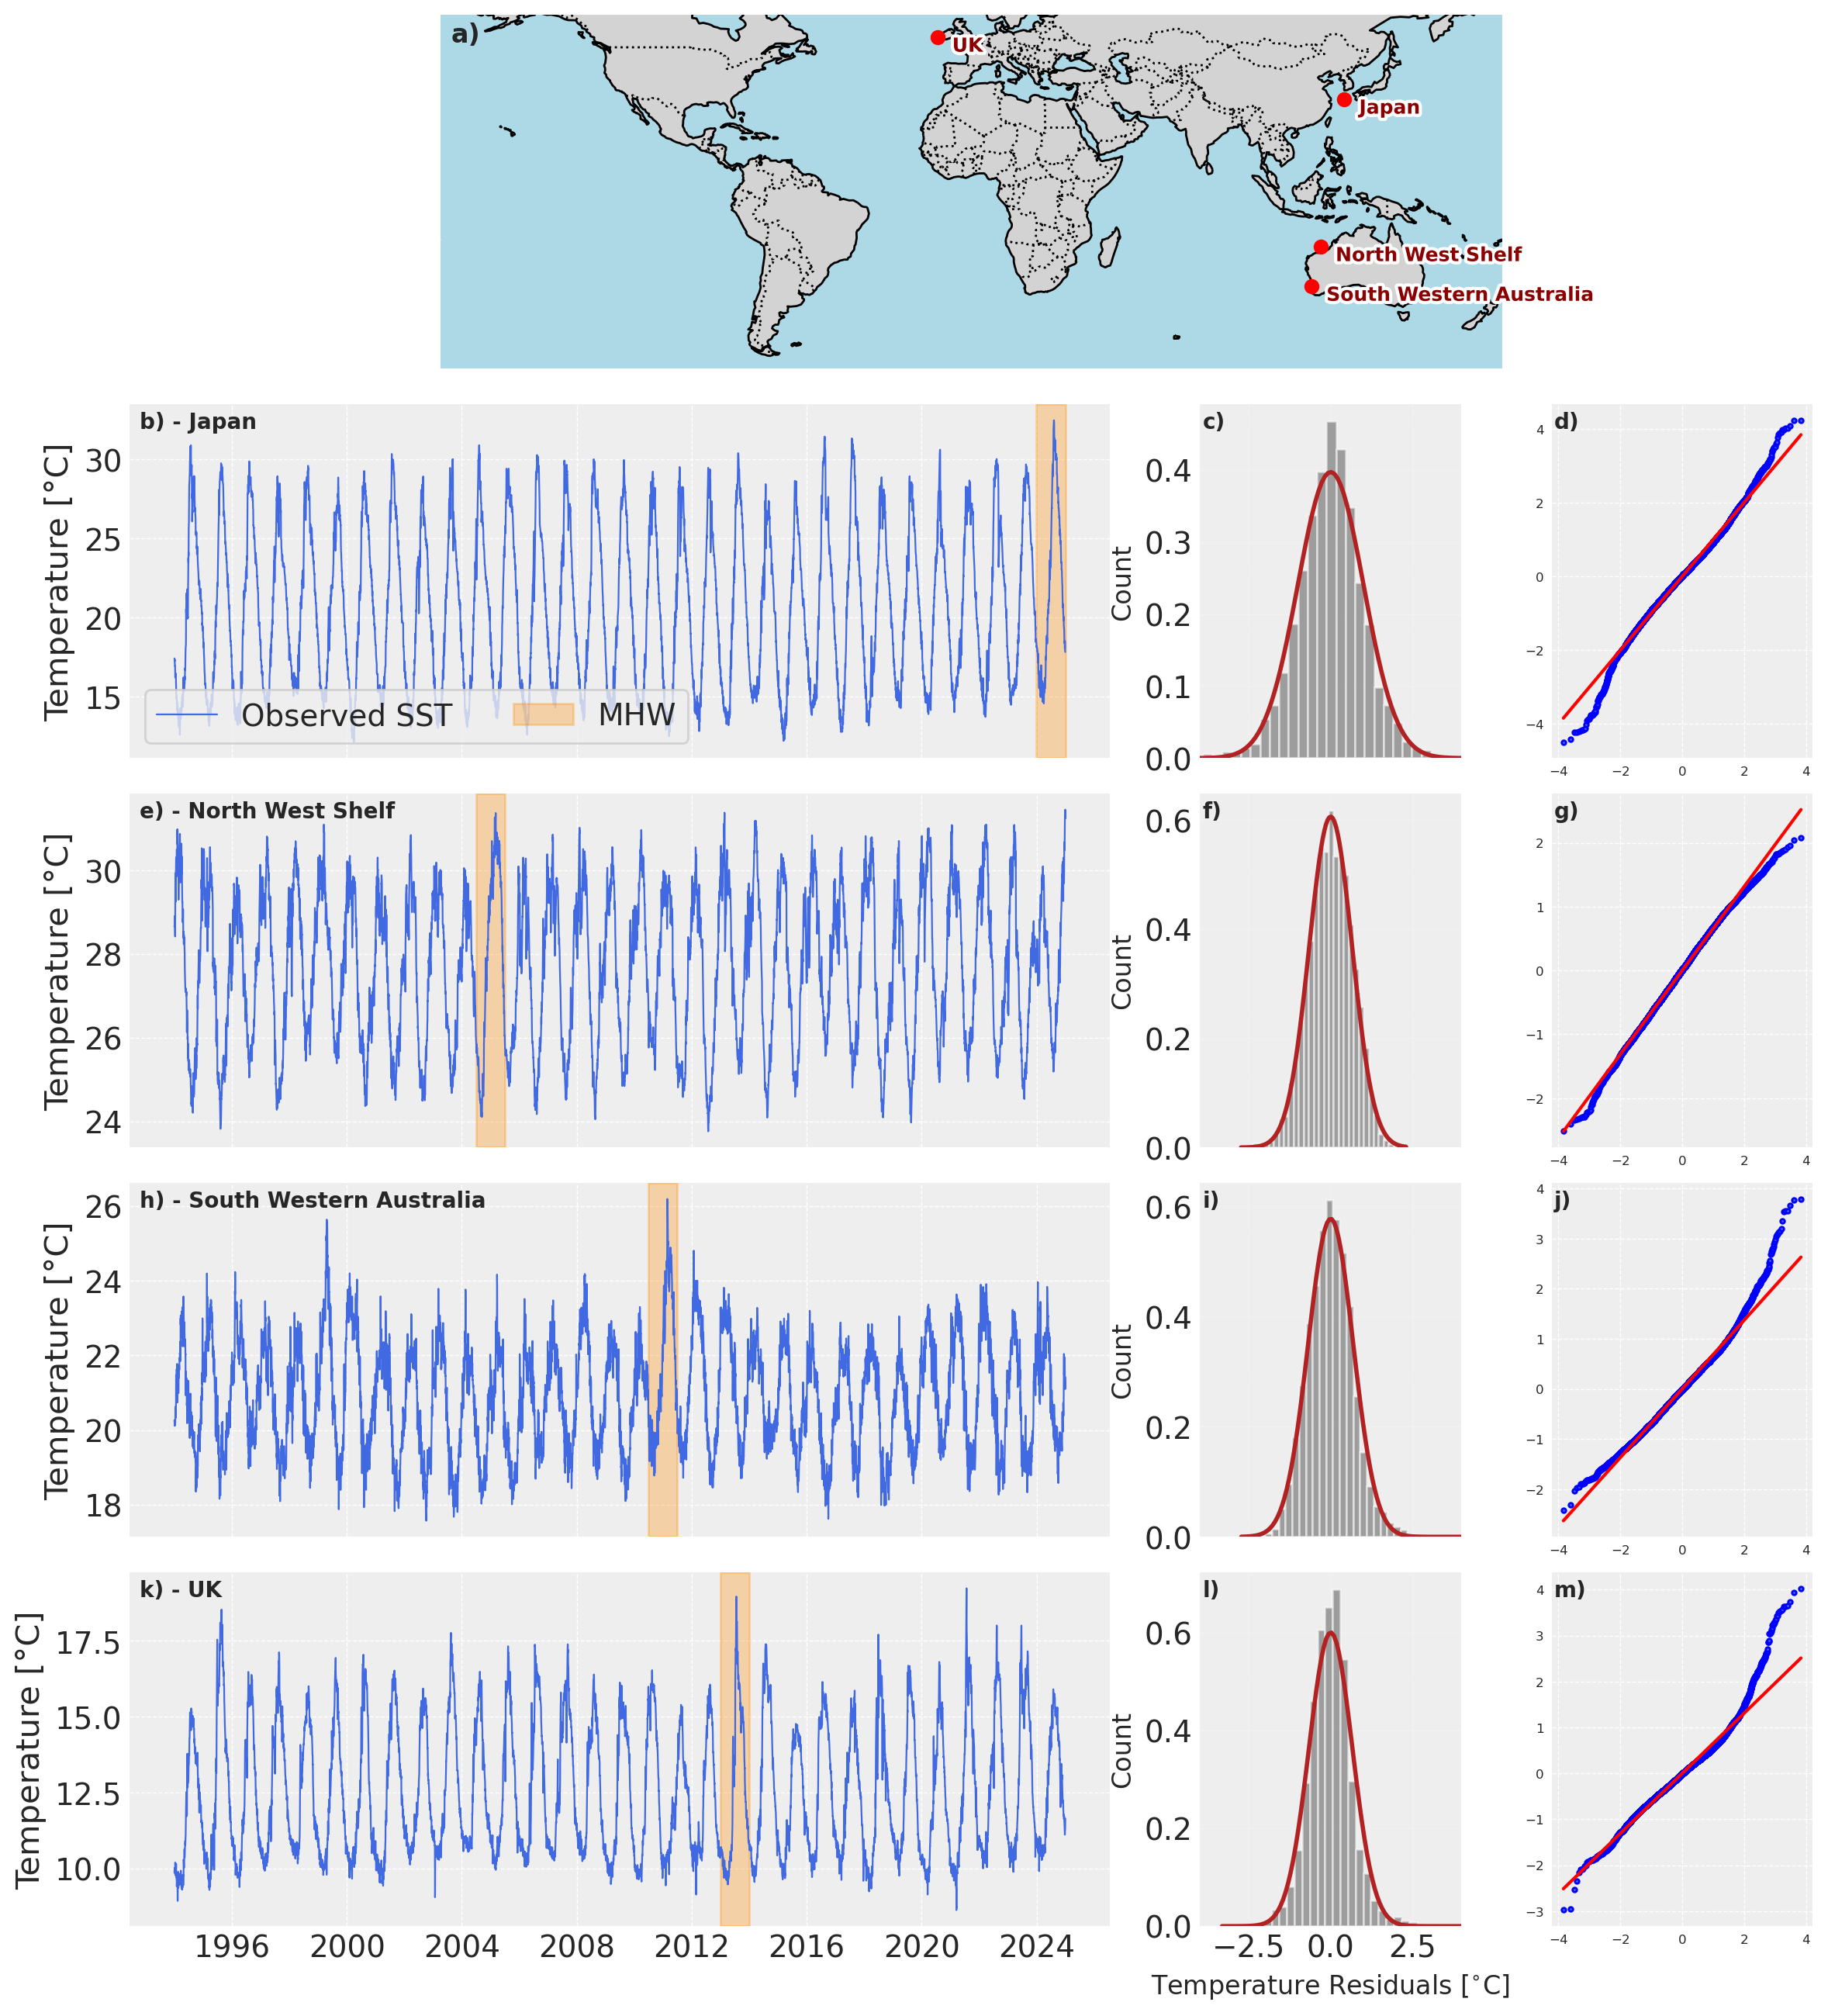

In [8]:



# --- Create figure with 2 rows: top (map), bottom (2x2 timeseries) ---
# fig = plt.figure(figsize=(14, 8), dpi=200)

import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 16), dpi=200)

gs = gridspec.GridSpec(
    nrows=5,
    ncols=3,
    figure=fig,
    width_ratios=[3, 0.8,0.8],     # ⬅ timeseries wider than histograms
    height_ratios=[1, 1, 1, 1, 1],  # ⬅ taller map
    hspace=0.1,
    wspace=0.18
)

# --- Map (top, centered across both columns) ---
ax_map = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())
ax_map.set_global()
ax_map.coastlines()
ax_map.add_feature(cfeature.BORDERS, linestyle=":")
ax_map.add_feature(cfeature.LAND, facecolor="lightgray")
ax_map.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax_map.set_ylim(-60, 60)

# --- Left column: timeseries ---
axes_ts = [fig.add_subplot(gs[i, 0]) for i in range(1, 5)]

# --- Right column: histograms ---
axes_his = [fig.add_subplot(gs[i, 1]) for i in range(1, 5)]

# --- Right column: histograms ---
axes_qq = [fig.add_subplot(gs[i, 2]) for i in range(1, 5)]

panel_labels = ['a)', 'b)', 'e)', 'h)', 'k)']
panel_labels2 =      ['c)', 'f)', 'i)', 'l)']
panel_labels3 =      ['d)', 'g)', 'j)', 'm)']
# --- Plot data ---
# Map
for ii, ((lon, lat, fname), (time, ts)) in enumerate(zip(locations, timeseries)):
    print(lon, lat, fname)
    ax_map.plot(lon, lat, "ro", markersize=6, transform=ccrs.PlateCarree())
    txt = ax_map.text(lon + 5, lat, labels[ii], transform=ccrs.PlateCarree(),
                fontsize=9, va='top', weight='bold', color='darkred')
    txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

# Add panel label to map
ax_map.text(0.01, 0.98, panel_labels[0], transform=ax_map.transAxes,
            ha='left', va='top', fontsize=12, weight='bold')

ax_map.set_ylim(-60,60)


# Timeseries
for ii, ((lon, lat, fname), (time, ts)) in enumerate(zip(locations, timeseries)):
    ax = axes_ts[ii]
    ax.plot(time, ts - 273.15, color="royalblue", linewidth=0.8,label='Observed SST')
    
    if ii < 3:  # hide x labels on top row of bottom grid
        ax.set_xticklabels([])
    # Panel label
    ax.text(0.01, 0.98, f"{panel_labels[ii+1]} - {labels[ii]}", transform=ax.transAxes,
            ha='left', va='top', fontsize=10, weight='bold')



    hemis = get_hemisphere(lat)
    df_C = pd.DataFrame()
    df_C['Mean'] = np.zeros(len(ts - 273.15 )) + np.nanmean(ts - 273.15)
    df_C['Temp'] = ts - 273.15
    df_C.index = time 
    if hemis == 'Northern Hemisphere': 
        df_C = df_C.loc[pd.to_datetime("1995-01-01"):]
    elif hemis == 'Southern Hemisphere':
        df_C = df_C.loc[pd.to_datetime("1994-07-01"):pd.to_datetime("2024-06-30")]
    df_C_roll =  df_C.rolling(7, min_periods=1, center=True).mean().copy()
    mhws_30yrs, clim_30yrs, times_dates_mhw_30yrs  = comparing_to_Hobday(df_C_roll.Temp)
    df_C['seas'] = clim_30yrs['seas']
    df_hist = df_C.Temp - df_C.seas

    from scipy import stats

    # ... inside your loop ...
    df_hist = df_C.Temp - df_C.seas
    df_hist_clean = df_hist.dropna() # Shapiro-Wilk hates NaNs
    
    # 1. Run Shapiro-Wilk Test
    shapiro_stat, p_val = stats.shapiro(df_hist_clean)
    
    # 2. Plot Histogram with Normal Fit Overlay
    ax = axes_his[ii]
    n, bins, patches = ax.hist(df_hist, bins=30, density=True, alpha=0.5, color="0.3", edgecolor="white")
    
    # Calculate Normal PDF based on the data's mean/std
    mu, std = stats.norm.fit(df_hist_clean)
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, mu, std)
    ax.plot(x, p, 'r', linewidth=2, label='Normal Fit', color ='firebrick') # The Red Line
    ax.set_xlim(-4,4)
    if ii < 3:  # hide x labels on top row of bottom grid
        ax.set_xticklabels([])
    # cosmetic improvements
    if ii == 3:
        ax.set_xlabel("Temperature Residuals [$^{\circ}$C]", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    
    # cleaner gridlines
    ax.grid(alpha=0.3, linestyle="--")
    ax.text(0.01, 0.98, f"{panel_labels2[ii]}", transform=ax.transAxes,
            ha='left', va='top', fontsize=10, weight='bold')

    
    
    # 3. Add Inset Q-Q Plot (This is the "Gold Standard" for Reviewers)
    # from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    ax_ins = axes_qq[ii]
    stats.probplot(df_hist_clean, dist="norm", plot=ax_ins)
    ax_ins.set_title("") # Clean up inset labels
    ax_ins.set_xlabel("")
    ax_ins.set_ylabel("")
    ax_ins.tick_params(labelsize=6)
    # Color the Q-Q points to match your theme
    ax_ins.get_lines()[0].set_markerfacecolor('royalblue')
    ax_ins.get_lines()[0].set_markersize(2)
    ax_ins.text(0.01, 0.98, f"{panel_labels3[ii]}", transform=ax_ins.transAxes,
            ha='left', va='top', fontsize=10, weight='bold')
    
    # 4. Text label for P-Value
    # p_text = f"Shapiro p:\n{p_val:.3f}" if p_val > 0.001 else "Shapiro p\n< 0.001"
    # ax.text(0.05, 0.75, p_text, transform=ax.transAxes, fontsize=9, fontweight='bold', color='red')


    

# --- Highlight MHW events ---


ax = axes_ts[0]
ds_start,ds_end = pd.to_datetime('2024-01-01'),pd.to_datetime('2025-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3, label = 'MHW')
ax.set_ylabel("Temperature [°C]")
ax.legend(loc = 'lower left', ncols = 2, frameon=True)

ax = axes_ts[1]
ds_start,ds_end = pd.to_datetime('2004-07-01'),pd.to_datetime('2005-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")


ax = axes_ts[2]
ds_start,ds_end = pd.to_datetime('2010-07-01'),pd.to_datetime('2011-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")


ax = axes_ts[3]
ds_start,ds_end = pd.to_datetime('2013-01-01'),pd.to_datetime('2014-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")




# Adjust layout
plt.tight_layout()

# plt.savefig(os.path.join(current_folder, "Figures", "Figure_01b.png"), dpi=300, bbox_inches="tight")
# plt.savefig(os.path.join(current_folder, "Figures", "Figure_01b.pdf"), dpi=300, bbox_inches="tight")


plt.show()




C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10958.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10958.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10958.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current

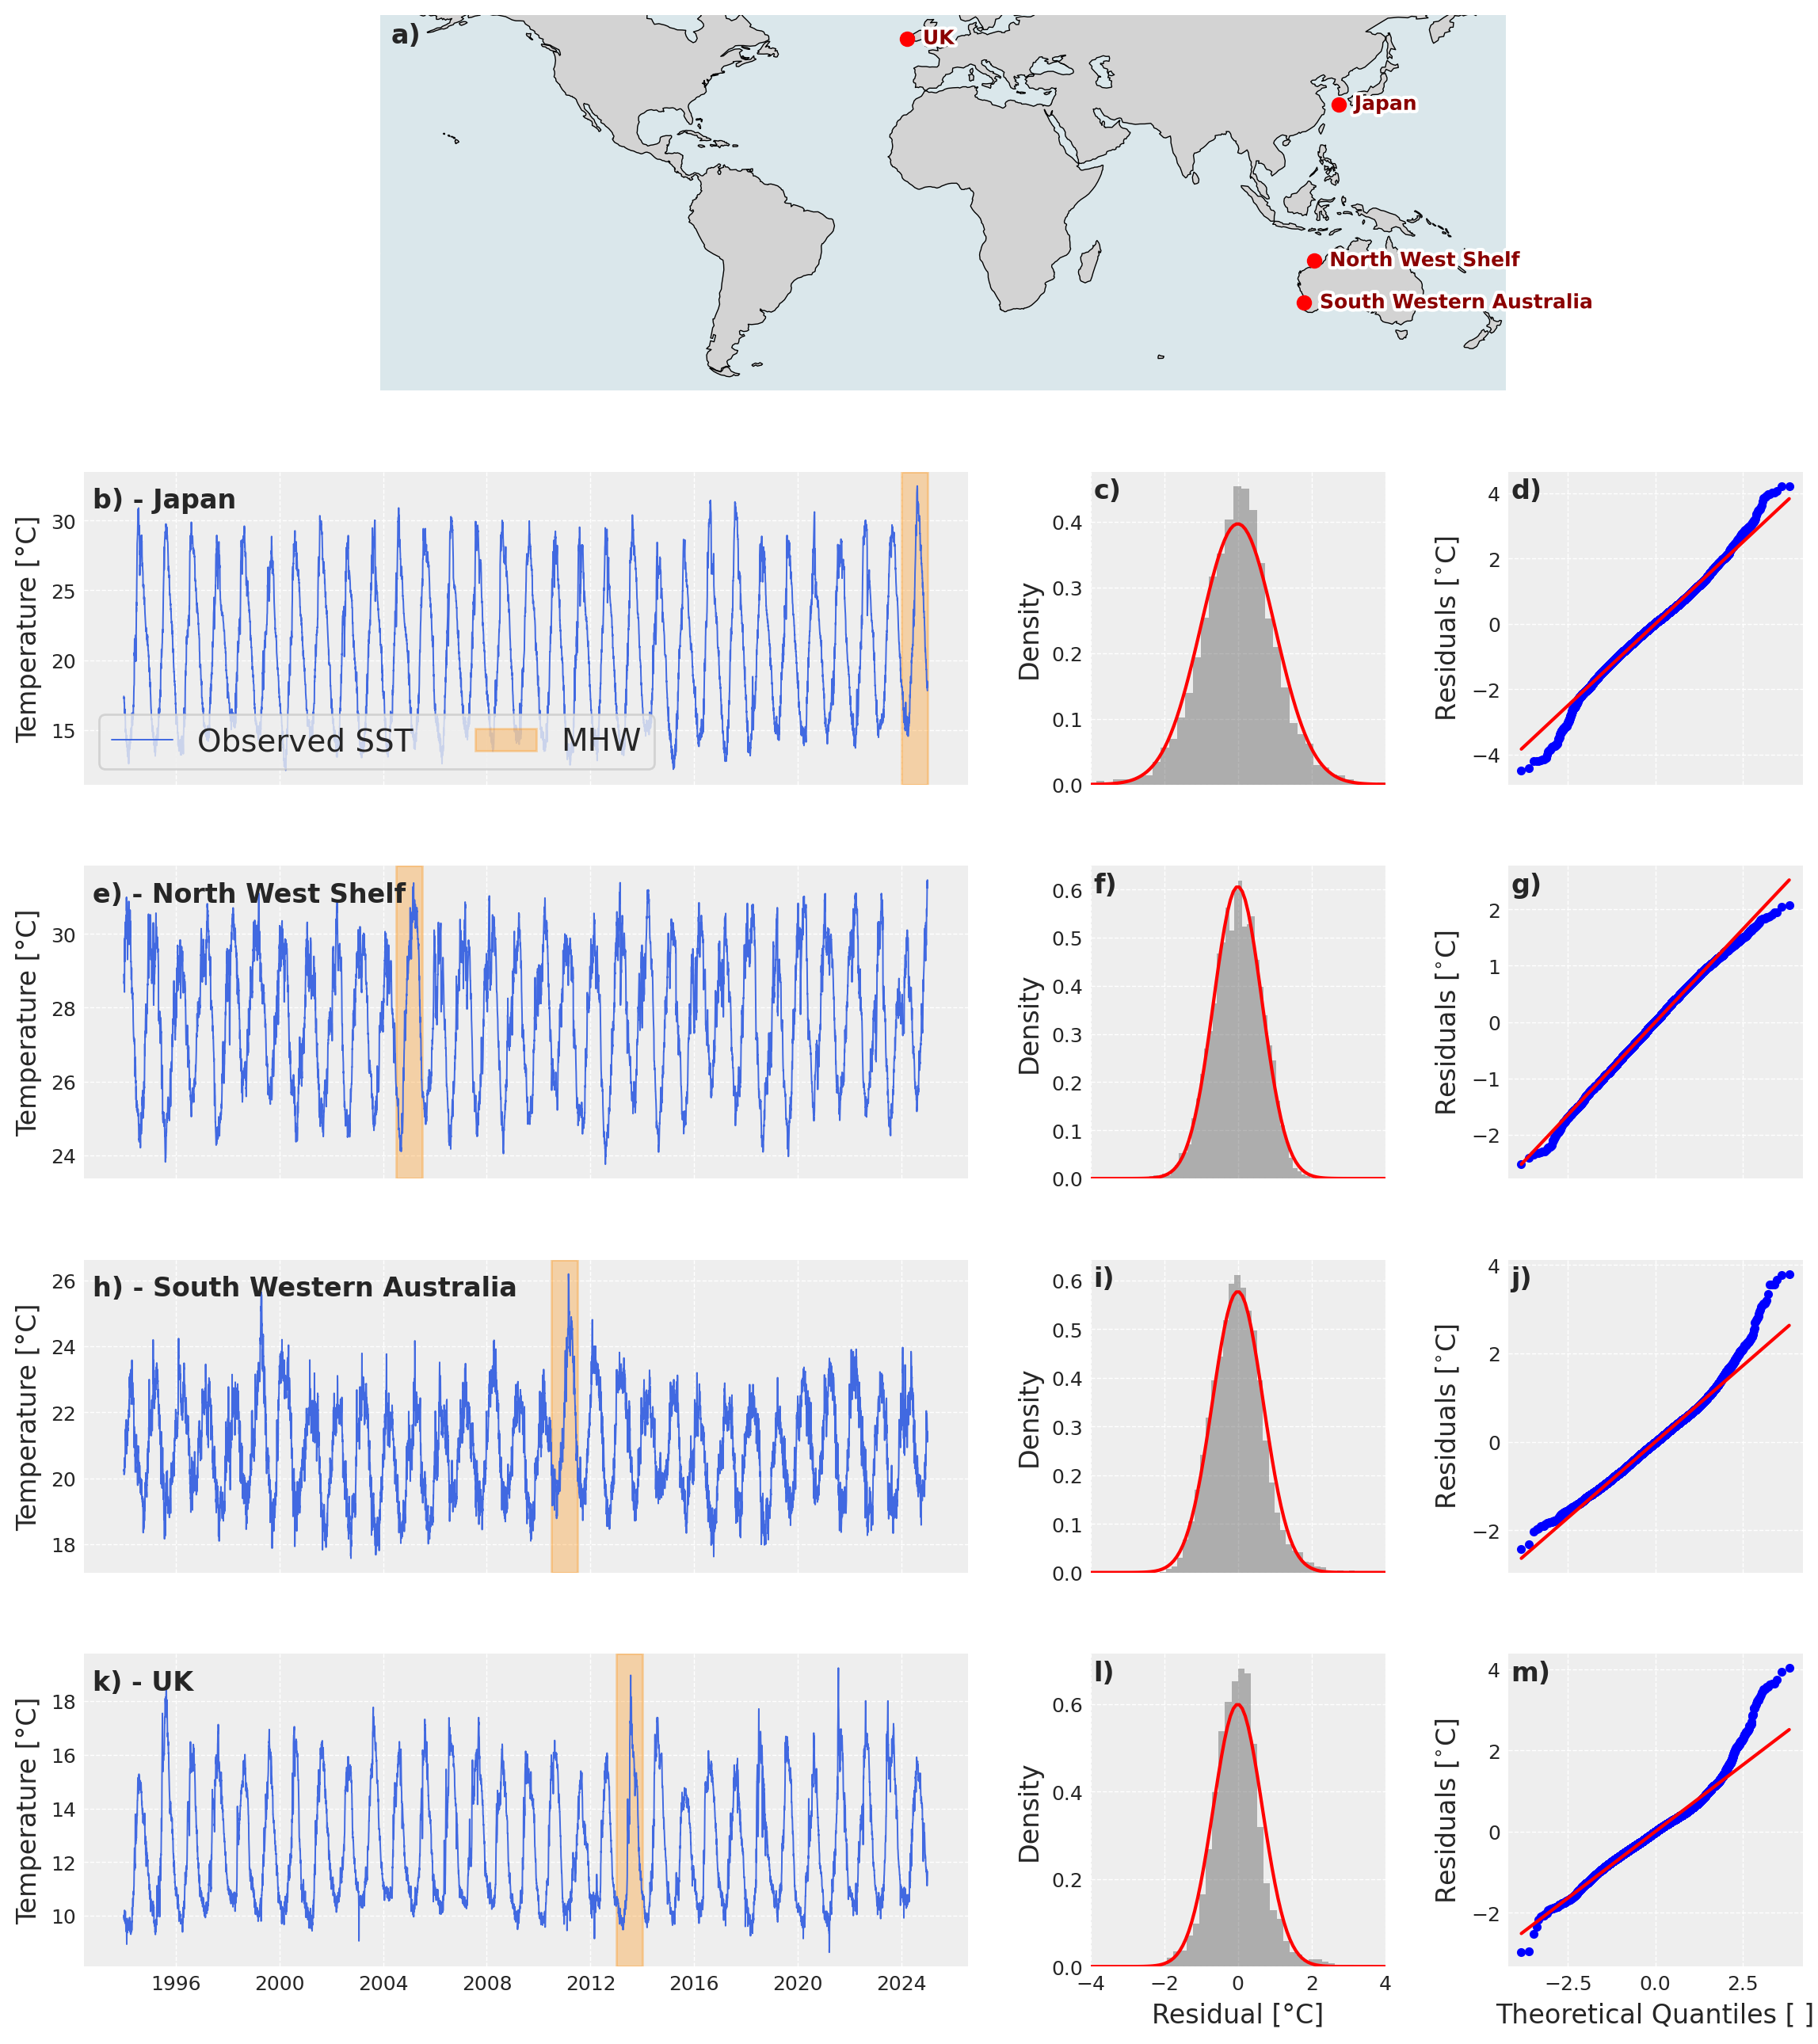

In [11]:
import matplotlib.gridspec as gridspec
from scipy import stats
import matplotlib.patheffects as PathEffects

# Standardizing font sizes for a "Nature" style
TITLE_FONT = 12
LABEL_FONT = 12
TICK_FONT = 9

fig = plt.figure(figsize=(14, 16), dpi=200)

gs = gridspec.GridSpec(
    nrows=5,
    ncols=3,
    figure=fig,
    width_ratios=[3, 1, 1],         
    height_ratios=[1.2, 1, 1, 1, 1], 
    hspace=0.25,
    wspace=0.25
)

# --- Map (top) ---
ax_map = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())
ax_map.set_global()
ax_map.coastlines(linewidth=0.5)
ax_map.add_feature(cfeature.LAND, facecolor="lightgray")
ax_map.add_feature(cfeature.OCEAN, facecolor="lightblue", alpha=0.3)
ax_map.set_ylim(-60, 60)

# --- Subplot Lists ---
axes_ts = [fig.add_subplot(gs[i, 0]) for i in range(1, 5)]
axes_his = [fig.add_subplot(gs[i, 1]) for i in range(1, 5)]
axes_qq = [fig.add_subplot(gs[i, 2]) for i in range(1, 5)]

panel_labels = ['a)', 'b)', 'e)', 'h)', 'k)']
panel_labels2 = ['c)', 'f)', 'i)', 'l)']
panel_labels3 = ['d)', 'g)', 'j)', 'm)']

# --- Plotting Loop ---
for ii, ((lon, lat, fname), (time, ts)) in enumerate(zip(locations, timeseries)):
    
    # 1. Map Markers
    ax_map.plot(lon, lat, "ro", markersize=6, transform=ccrs.PlateCarree())
    txt = ax_map.text(lon + 5, lat, labels[ii], transform=ccrs.PlateCarree(),
                fontsize=TICK_FONT, va='center', weight='bold', color='darkred')
    txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

    # 2. Timeseries
    ax = axes_ts[ii]
    temp_c = ts - 273.15
    ax.plot(time, temp_c, color="royalblue", linewidth=0.7, label='Observed SST' if ii==0 else "")
    ax.set_ylabel("Temp [°C]", fontsize=LABEL_FONT)
    ax.tick_params(labelsize=TICK_FONT)
    
    if ii < 3: ax.set_xticklabels([])
    ax.text(0.01, 0.95, f"{panel_labels[ii+1]} - {labels[ii]}", transform=ax.transAxes,
            ha='left', va='top', fontsize=LABEL_FONT, weight='bold')

    # 3. Data Processing for Residuals
    hemis = get_hemisphere(lat)
   
    df_C = pd.DataFrame()
    df_C['Mean'] = np.zeros(len(ts - 273.15 )) + np.nanmean(ts - 273.15)
    df_C['Temp'] = ts - 273.15
    df_C.index = time 
    if hemis == 'Northern Hemisphere': 
        df_C = df_C.loc[pd.to_datetime("1995-01-01"):]
    elif hemis == 'Southern Hemisphere':
        df_C = df_C.loc[pd.to_datetime("1994-07-01"):pd.to_datetime("2024-06-30")]
    df_C_roll =  df_C.rolling(7, min_periods=1, center=True).mean().copy()
    mhws_30yrs, clim_30yrs, times_dates_mhw_30yrs  = comparing_to_Hobday(df_C_roll.Temp)
    df_C['seas'] = clim_30yrs['seas']
    df_hist = df_C.Temp - df_C.seas

    from scipy import stats

    # ... inside your loop ...
    df_hist = df_C.Temp - df_C.seas
    df_hist_clean = df_hist.dropna()

    # 4. Histogram & Normal Fit
    ax_h = axes_his[ii]
    mu, std = stats.norm.fit(df_hist_clean)
    ax_h.hist(df_hist_clean, bins=40, density=True, alpha=0.4, color="0.3", edgecolor="none")
    
    x = np.linspace(-4, 4, 100)
    ax_h.plot(x, stats.norm.pdf(x, mu, std), 'r-', linewidth=1.5)
    ax_h.set_xlim(-4, 4)
    ax_h.tick_params(labelsize=TICK_FONT)
    ax_h.set_ylabel("Density", fontsize=LABEL_FONT)
    if ii < 3: ax_h.set_xticklabels([])
    if ii == 3: ax_h.set_xlabel("Residual [°C]", fontsize=LABEL_FONT)
    
    ax_h.text(0.01, 0.98, panel_labels2[ii], transform=ax_h.transAxes, ha='left', va='top',weight='bold', fontsize=LABEL_FONT)
    
    # Shapiro Text
    _, p_val = stats.shapiro(df_hist_clean)
    p_str = "$p < 0.001$" if p_val < 0.001 else f"$p = {p_val:.3f}$"
    # ax_h.text(0.05, 0.82, f"Shapiro:\n{p_str}", transform=ax_h.transAxes, fontsize=8, color='red')

    # 5. Q-Q Plot
    ax_q = axes_qq[ii]
    stats.probplot(df_hist_clean, dist="norm", plot=ax_q)
    
    # # Styling Q-Q
    # ax_q.get_lines()[0].set_markerfacecolor('royalblue')
    # ax_q.get_lines()[0].set_markeredgecolor('white')
    # ax_q.get_lines()[0].set_markeredgewidth(0.5)
    ax_q.get_lines()[0].set_markersize(3)
    # ax_q.get_lines()[1].set_color('red')
    # ax_q.get_lines()[1].set_linewidth(1.5)
    
    ax_q.set_title("")
    ax_q.tick_params(labelsize=TICK_FONT)
    if ii < 3: 
        ax_q.set_xlabel("")
        ax_q.set_xticklabels([])
    else:
        ax_q.set_xlabel("Theoretical Quantiles [ ]", fontsize=LABEL_FONT)
    
    ax_q.set_ylabel("Residuals [$^{\circ}$C]", fontsize=LABEL_FONT)
    ax_q.text(0.01, 0.98, panel_labels3[ii], transform=ax_q.transAxes,ha='left', va='top', weight='bold', fontsize=LABEL_FONT)

# Highlight MHW Example on panel B
# --- Highlight MHW events ---
ax = axes_ts[0]
ds_start,ds_end = pd.to_datetime('2024-01-01'),pd.to_datetime('2025-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3, label = 'MHW')
ax.set_ylabel("Temperature [°C]")
ax.legend(loc = 'lower left', ncols = 2, frameon=True)

ax = axes_ts[1]
ds_start,ds_end = pd.to_datetime('2004-07-01'),pd.to_datetime('2005-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")

ax = axes_ts[2]
ds_start,ds_end = pd.to_datetime('2010-07-01'),pd.to_datetime('2011-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")

ax = axes_ts[3]
ds_start,ds_end = pd.to_datetime('2013-01-01'),pd.to_datetime('2014-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")



# Add map label
ax_map.text(0.01, 0.98, panel_labels[0], transform=ax_map.transAxes, ha='left', va='top', fontsize=LABEL_FONT, weight='bold')

plt.tight_layout()
plt.savefig(os.path.join(current_folder, "Figures", "Figure_01.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(current_folder, "Figures", "Figure_01.pdf"), dpi=300, bbox_inches="tight")

plt.show()